# 흉부 X-ray 폐렴 분류 (NORMAL vs PNEUMONIA)

## 1. 라이브러리 & 설정

In [1]:
import os, random, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score

print("torch", torch.__version__)

# 한글 폰트 지정
from matplotlib import font_manager
_installed = {f.name for f in font_manager.fontManager.ttflist}
for _font in ["AppleGothic", "Malgun Gothic", "NanumGothic", "Noto Sans CJK KR"]:
    if _font in _installed:
        plt.rcParams["font.family"] = _font
        break
plt.rcParams["axes.unicode_minus"] = False

torch 2.14.0


In [2]:
CFG = dict(
    DATA_DIR    = next(p for p in ["../../data"] if os.path.exists(os.path.join(p, "train.csv"))),  # 노트북 위치에 따라 자동 탐색
    OUT_DIR     = "../../outputs",
    IMG_SIZE    = 224,
    BATCH_SIZE  = 32,
    EPOCHS      = 12,
    LR          = 3e-4,
    WEIGHT_DECAY= 1e-4,
    PATIENCE    = 4,                # 검증 성능이 이 epoch 수만큼 개선 없으면 조기 종료
    N_FOLDS     = 5,
    FOLDS_TO_RUN= [0],              # [0] = 빠른 실행(1개 fold). [0,1,2,3,4]로 바꾸면 5-fold 앙상블
    PRETRAINED  = True,             # ImageNet 사전학습 가중치 사용
    TTA         = True,
    SEED        = 42,
)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
seed_everything(CFG["SEED"])

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():     # Apple Silicon GPU
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("device:", device)

os.makedirs(CFG["OUT_DIR"], exist_ok=True)
D = CFG["DATA_DIR"]

device: mps


## 2. 데이터 살펴보기 (EDA)

In [3]:
train_df = pd.read_csv(os.path.join(D, "train.csv"))
test_df  = pd.read_csv(os.path.join(D, "test.csv"))
CLASSES = ["NORMAL", "PNEUMONIA"]

print("train:", train_df.shape, " test:", test_df.shape)
print(train_df["label"].value_counts().rename(index=dict(enumerate(CLASSES))))

def img_size(path):
    with Image.open(path) as im: return im.size
tr_sizes = pd.Series([img_size(os.path.join(D, "train", f)) for f in train_df.file_name[:200]]).value_counts()
te_sizes = [img_size(os.path.join(D, "test", f)) for f in test_df.file_name]
print("\ntrain 이미지 크기(앞 200장):", tr_sizes.to_dict())
print("test  이미지 크기 예시:", te_sizes[:5], "... 서로 다른 크기 수:", len(set(te_sizes)))

train: (5216, 2)  test: (624, 1)
label
PNEUMONIA    3875
NORMAL       1341
Name: count, dtype: int64

train 이미지 크기(앞 200장): {(224, 224): 200}
test  이미지 크기 예시: [(1936, 1554), (1612, 941), (1528, 968), (904, 552), (1365, 1118)] ... 서로 다른 크기 수: 598


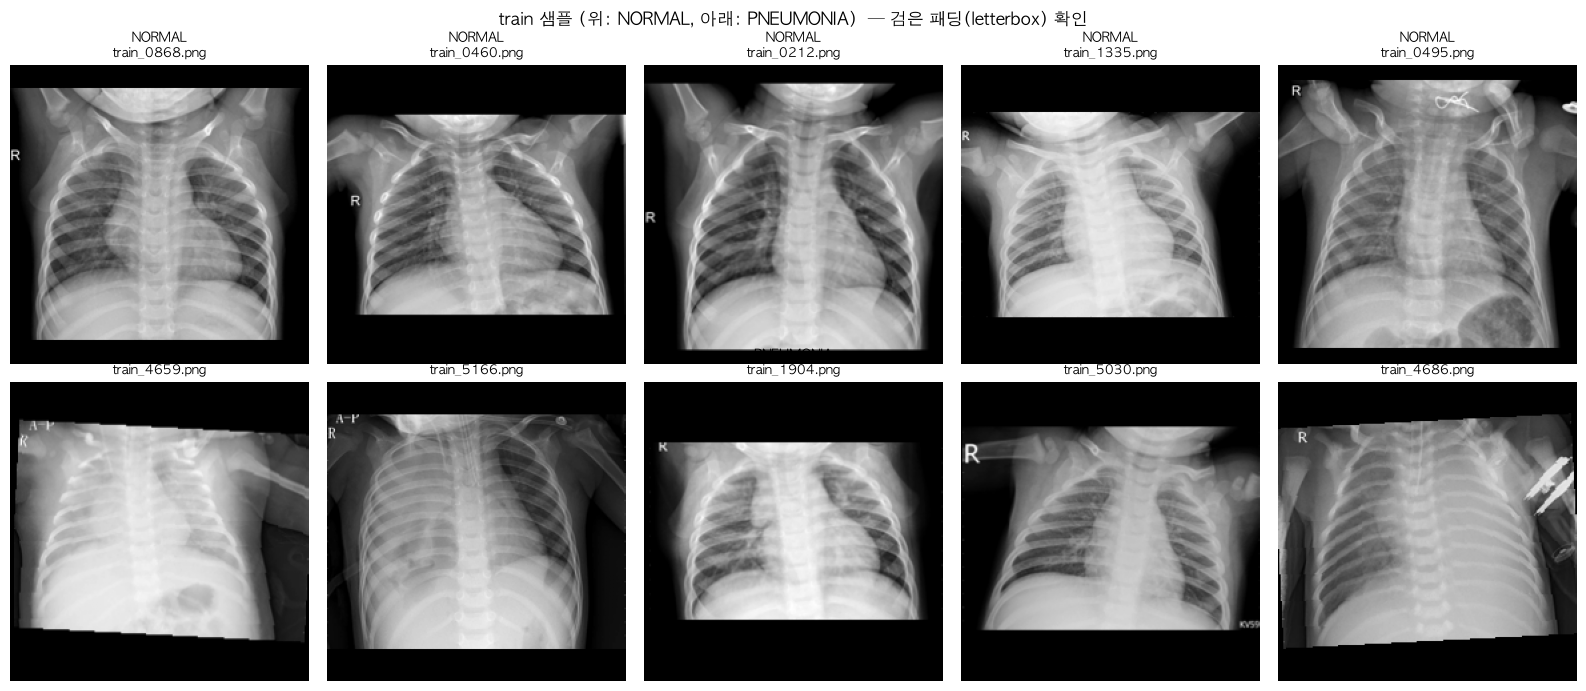

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for row, lab in enumerate([0, 1]):
    samples = train_df[train_df.label == lab].sample(5, random_state=0).file_name
    for ax, f in zip(axes[row], samples):
        ax.imshow(Image.open(os.path.join(D, "train", f)), cmap="gray")
        ax.set_title(f"{CLASSES[lab]}\n{f}", fontsize=9); ax.axis("off")
plt.suptitle("train 샘플 (위: NORMAL, 아래: PNEUMONIA)  — 검은 패딩(letterbox) 확인")
plt.tight_layout(); plt.show()

**데이터 확인 결과**
- `train/` : 5,216장, 모두 **224×224** 흑백. 원본 비율을 유지한 채 축소하고 위/아래(또는 좌/우)를 검은색으로 채운 letterbox 형태.
- `test/` : 624장, **원본 해상도(제각각)**  → 학습 이미지와 **똑같은 letterbox 전처리**를 해야 분포가 맞다.
- 라벨: `0 = NORMAL` 1,341장, `1 = PNEUMONIA` 3,875장 (약 1 : 2.9 불균형)

**대회 규칙 준수**
- 외부 데이터 사용 없음. 검증 데이터는 **train.csv를 나눠서**만 만들고, test 이미지는 제출 파일 생성(추론)에만 사용.

## 3. 전처리: letterbox

train 이미지가 만들어진 방식(비율 유지 축소 → 가운데 정렬 → 검은색 패딩)을 그대로 재현해서 test 이미지에도 적용한다.
train 이미지는 이미 224×224라 이 함수를 통과해도 그대로이다.

In [5]:
def letterbox(img: Image.Image, size: int) -> Image.Image:
    img = img.convert("L")
    w, h = img.size
    if (w, h) == (size, size):
        return img
    scale = size / max(w, h)
    nw, nh = max(1, round(w * scale)), max(1, round(h * scale))
    img = img.resize((nw, nh), Image.BILINEAR)
    canvas = Image.new("L", (size, size), 0)
    canvas.paste(img, ((size - nw) // 2, (size - nh) // 2))
    return canvas

def load_all(folder, files, size):
    return [letterbox(Image.open(os.path.join(D, folder, f)), size) for f in tqdm(files, desc=folder)]

train_imgs = load_all("train", train_df.file_name, CFG["IMG_SIZE"])
test_imgs  = load_all("test",  test_df.file_name,  CFG["IMG_SIZE"])
train_labels = train_df.label.astype(int).values

train:   0%|          | 0/5216 [00:00<?, ?it/s]

test:   0%|          | 0/624 [00:00<?, ?it/s]

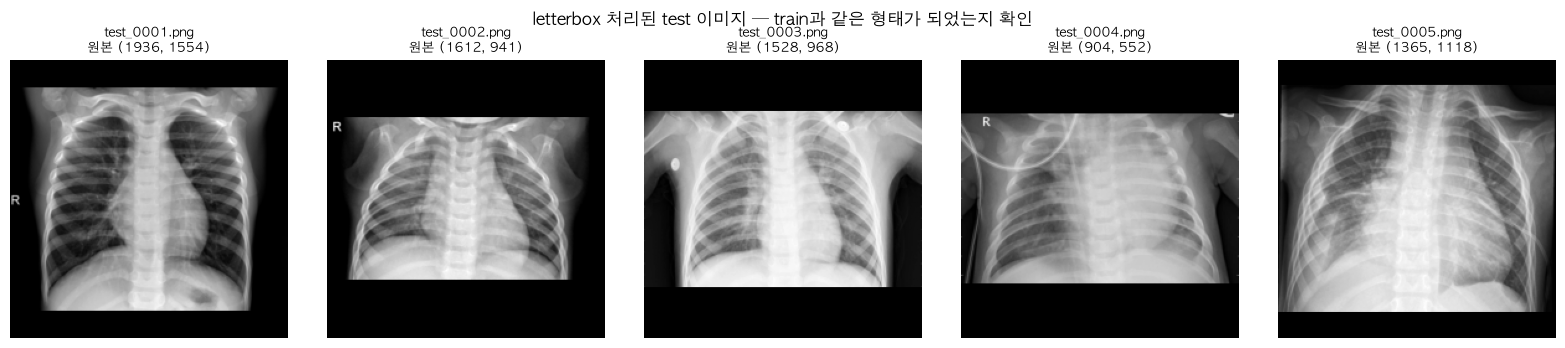

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
for ax, i in zip(axes, range(5)):
    ax.imshow(test_imgs[i], cmap="gray"); ax.set_title(f"{test_df.file_name[i]}\n원본 {te_sizes[i]}", fontsize=9); ax.axis("off")
plt.suptitle("letterbox 처리된 test 이미지 — train과 같은 형태가 되었는지 확인"); plt.tight_layout(); plt.show()

## 4. Dataset & 데이터 증강

- 흑백 1채널을 3채널로 복제해 ImageNet 사전학습 모델 입력에 맞추고, ImageNet 평균/표준편차로 정규화한다.
- 증강: 작은 회전·이동·확대, 밝기/대비 변화. X-ray는 좌우가 해부학적으로 다르고 테스트 이미지도 항상 같은 방향이므로 좌우 반전은 쓰지 않는다.

In [7]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomAffine(degrees=10, translate=(0.06, 0.06), scale=(0.9, 1.1), fill=0),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class XrayDataset(Dataset):
    def __init__(self, imgs, labels=None, tf=eval_tf):
        self.imgs, self.labels, self.tf = imgs, labels, tf
    def __len__(self): return len(self.imgs)
    def __getitem__(self, i):
        x = self.tf(self.imgs[i])
        if self.labels is None:
            return x
        return x, int(self.labels[i])

## 5. 모델: ResNet18 전이학습

ImageNet으로 미리 학습된 ResNet18의 특징 추출기를 가져오고, 마지막 분류층만 2클래스로 바꾼다.
(최초 실행 시 가중치 파일 약 45MB를 pytorch.org에서 내려받는다.)

In [8]:
def build_model(pretrained=CFG["PRETRAINED"]):
    weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    m = models.resnet18(weights=weights)
    m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.fc.in_features, 2))
    return m

print(sum(p.numel() for p in build_model().parameters()) / 1e6, "M params")

11.177538 M params


## 6. 학습 / 검증 함수

- **클래스 가중치**: PNEUMONIA가 NORMAL의 약 3배라 모델이 PNEUMONIA 쪽으로 치우치기 쉽다. 손실에서 NORMAL 오답에 더 큰 벌점을 줘서 균형을 맞춘다.
- **Label smoothing 0.05**: 과신(over-confidence)을 줄여 일반화에 도움.
- **AdamW + Cosine LR(warmup 1 epoch)**, **Early stopping**: 검증 정확도가 가장 높을 때의 가중치를 저장.

In [9]:
def make_loaders(tr_idx, va_idx):
    tr_ds = XrayDataset([train_imgs[i] for i in tr_idx], train_labels[tr_idx], train_tf)
    va_ds = XrayDataset([train_imgs[i] for i in va_idx], train_labels[va_idx], eval_tf)
    return (DataLoader(tr_ds, batch_size=CFG["BATCH_SIZE"], shuffle=True, drop_last=True),
            DataLoader(va_ds, batch_size=64, shuffle=False))

@torch.no_grad()
def predict_proba(model, loader, tta=False):
    """PNEUMONIA(1) 확률을 반환"""
    model.eval(); probs = []
    for batch in loader:
        x = batch[0] if isinstance(batch, (list, tuple)) else batch
        x = x.to(device)
        p = F.softmax(model(x), 1)
        if tta:  # 약한 TTA: 살짝 확대(가운데 crop 후 원래 크기로)한 버전과 평균
            s = x.shape[-1]; c = int(s * 0.06)
            xz = F.interpolate(x[..., c:s - c, c:s - c], size=(s, s), mode="bilinear", align_corners=False)
            p = (p + F.softmax(model(xz), 1)) / 2
        probs.append(p[:, 1].cpu())
    return torch.cat(probs).numpy()

def train_one_fold(fold, tr_idx, va_idx):
    seed_everything(CFG["SEED"] + fold)
    tr_loader, va_loader = make_loaders(tr_idx, va_idx)
    model = build_model().to(device)

    counts = np.bincount(train_labels[tr_idx], minlength=2)
    class_w = torch.tensor(counts.sum() / (2 * counts), dtype=torch.float32, device=device)
    criterion = nn.CrossEntropyLoss(weight=class_w, label_smoothing=0.05)
    optimizer = torch.optim.AdamW(model.parameters(), lr=CFG["LR"], weight_decay=CFG["WEIGHT_DECAY"])

    steps_per_epoch = len(tr_loader); total = CFG["EPOCHS"] * steps_per_epoch; warm = steps_per_epoch
    sched = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + np.cos(np.pi * (s - warm) / (total - warm))))

    hist = {"train_loss": [], "val_loss": [], "val_acc": []}
    best_acc, best_state, bad = -1, None, 0
    for ep in range(1, CFG["EPOCHS"] + 1):
        t0 = time.time(); model.train(); run = 0.0
        for x, y in tr_loader:
            x, y = x.to(device), y.to(device)
            loss = criterion(model(x), y)
            optimizer.zero_grad(); loss.backward(); optimizer.step(); sched.step()
            run += loss.item() * x.size(0)
        tr_loss = run / (steps_per_epoch * CFG["BATCH_SIZE"])

        # 검증
        model.eval(); vl = 0.0; preds = []
        with torch.no_grad():
            for x, y in va_loader:
                x, y = x.to(device), y.to(device)
                out = model(x); vl += criterion(out, y).item() * x.size(0)
                preds.append(out.argmax(1).cpu())
        vl /= len(va_idx); va_acc = accuracy_score(train_labels[va_idx], torch.cat(preds).numpy())
        for k, v in zip(hist, (tr_loss, vl, va_acc)): hist[k].append(v)

        flag = ""
        if va_acc > best_acc:
            best_acc, best_state, bad, flag = va_acc, copy.deepcopy(model.state_dict()), 0, "  ★ best"
        else:
            bad += 1
        print(f"[fold {fold}] ep {ep:02d} | train_loss {tr_loss:.4f} | val_loss {vl:.4f} | val_acc {va_acc:.4f} | {time.time()-t0:.0f}s{flag}")
        if bad >= CFG["PATIENCE"]:
            print(f"  early stopping (patience {CFG['PATIENCE']})"); break

    model.load_state_dict(best_state)
    torch.save(best_state, os.path.join(CFG["OUT_DIR"], f"resnet18_fold{fold}.pt"))
    return model, hist, best_acc

## 7. Stratified K-Fold 학습

train.csv를 라벨 비율을 유지한 채 5등분해서 1개를 검증용으로 사용 (80% 학습 / 20% 검증).
기본값은 fold 0 하나만 학습.

In [10]:
skf = StratifiedKFold(n_splits=CFG["N_FOLDS"], shuffle=True, random_state=CFG["SEED"])
splits = list(skf.split(np.zeros(len(train_labels)), train_labels))

oof = np.full(len(train_labels), np.nan)        # 각 이미지가 검증셋일 때의 예측 확률
test_probs, histories, fold_scores = [], {}, {}

test_loader = DataLoader(XrayDataset(test_imgs, None, eval_tf), batch_size=64, shuffle=False)

for fold in CFG["FOLDS_TO_RUN"]:
    tr_idx, va_idx = splits[fold]
    model, hist, best = train_one_fold(fold, tr_idx, va_idx)
    histories[fold], fold_scores[fold] = hist, best

    _, va_loader = make_loaders(tr_idx, va_idx)
    oof[va_idx] = predict_proba(model, va_loader, tta=CFG["TTA"])
    test_probs.append(predict_proba(model, test_loader, tta=CFG["TTA"]))
    print(f"fold {fold} best val acc = {best:.4f}\n")

print("fold별 best val acc:", {k: round(v, 4) for k, v in fold_scores.items()})

[fold 0] ep 01 | train_loss 0.3318 | val_loss 0.2985 | val_acc 0.9722 | 40s  ★ best
[fold 0] ep 02 | train_loss 0.2401 | val_loss 0.2438 | val_acc 0.9828 | 60s  ★ best
[fold 0] ep 03 | train_loss 0.2113 | val_loss 0.2624 | val_acc 0.9693 | 59s
[fold 0] ep 04 | train_loss 0.2011 | val_loss 0.2359 | val_acc 0.9875 | 60s  ★ best
[fold 0] ep 05 | train_loss 0.1946 | val_loss 0.2500 | val_acc 0.9780 | 60s
[fold 0] ep 06 | train_loss 0.1895 | val_loss 0.2320 | val_acc 0.9904 | 60s  ★ best
[fold 0] ep 07 | train_loss 0.1764 | val_loss 0.2470 | val_acc 0.9828 | 60s
[fold 0] ep 08 | train_loss 0.1721 | val_loss 0.2240 | val_acc 0.9923 | 60s  ★ best
[fold 0] ep 09 | train_loss 0.1735 | val_loss 0.2324 | val_acc 0.9847 | 59s
[fold 0] ep 10 | train_loss 0.1670 | val_loss 0.2251 | val_acc 0.9904 | 60s
[fold 0] ep 11 | train_loss 0.1677 | val_loss 0.2236 | val_acc 0.9923 | 60s
[fold 0] ep 12 | train_loss 0.1653 | val_loss 0.2235 | val_acc 0.9914 | 60s
  early stopping (patience 4)
fold 0 best val ac

## 8. 학습 곡선

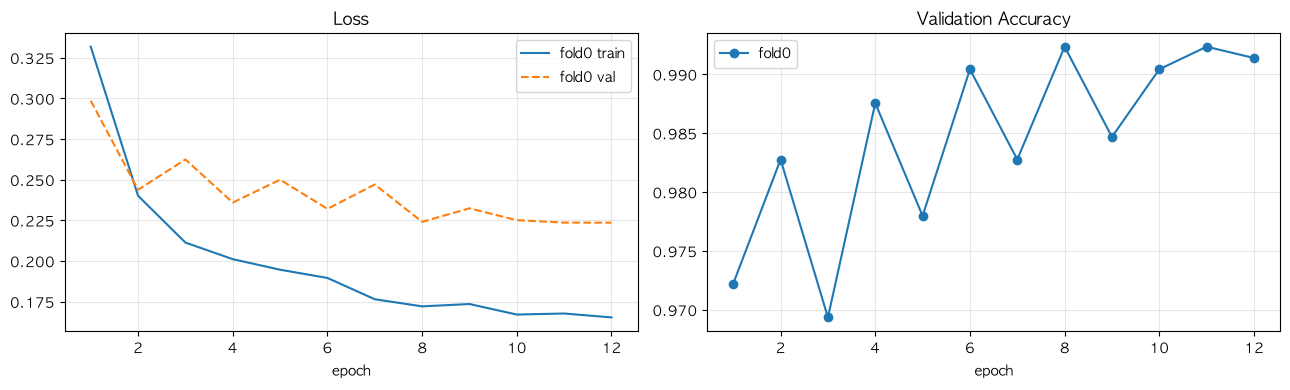

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for fold, h in histories.items():
    e = range(1, len(h["train_loss"]) + 1)
    axes[0].plot(e, h["train_loss"], "-",  label=f"fold{fold} train")
    axes[0].plot(e, h["val_loss"],   "--", label=f"fold{fold} val")
    axes[1].plot(e, h["val_acc"], marker="o", label=f"fold{fold}")
axes[0].set_title("Loss"); axes[1].set_title("Validation Accuracy")
for ax in axes: ax.set_xlabel("epoch"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 9. 검증 성능 분석

검증셋(학습에 쓰지 않은 train 일부)에 대한 정확도, 혼동행렬, 클래스별 정밀도/재현율을 확인한다.

Validation Accuracy : 0.9933
Validation ROC-AUC  : 0.9986

              precision    recall  f1-score   support

      NORMAL     0.9816    0.9926    0.9871       269
   PNEUMONIA     0.9974    0.9935    0.9955       775

    accuracy                         0.9933      1044
   macro avg     0.9895    0.9931    0.9913      1044
weighted avg     0.9933    0.9933    0.9933      1044



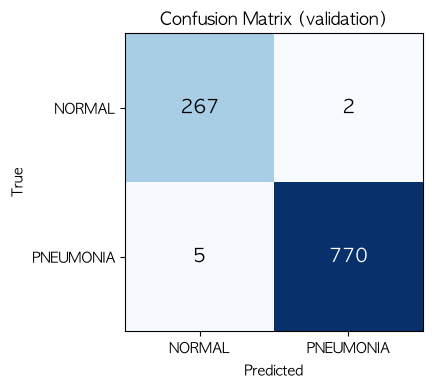

In [12]:
mask = ~np.isnan(oof)
y_true, y_prob = train_labels[mask], oof[mask]
y_pred = (y_prob >= 0.5).astype(int)

print(f"Validation Accuracy : {accuracy_score(y_true, y_pred):.4f}")
print(f"Validation ROC-AUC  : {roc_auc_score(y_true, y_prob):.4f}\n")
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1], CLASSES); ax.set_yticks([0, 1], CLASSES)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Confusion Matrix (validation)")
plt.tight_layout(); plt.show()

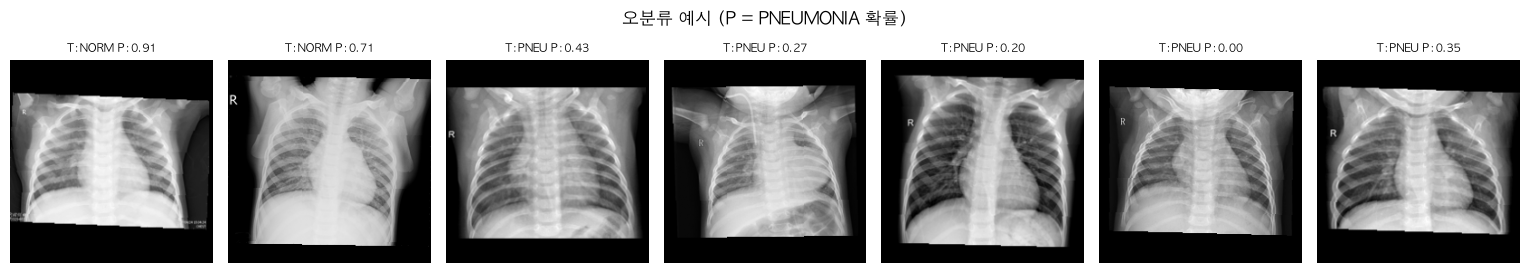

In [13]:
# 틀린 예측 몇 개인지 확인
wrong = np.where(mask)[0][y_pred != y_true]
n = min(8, len(wrong))
if n:
    fig, axes = plt.subplots(1, n, figsize=(2.2 * n, 2.8))
    axes = np.atleast_1d(axes)
    for ax, i in zip(axes, wrong[:n]):
        ax.imshow(train_imgs[i], cmap="gray"); ax.axis("off")
        ax.set_title(f"T:{CLASSES[train_labels[i]][:4]} P:{oof[i]:.2f}", fontsize=8)
    plt.suptitle("오분류 예시 (P = PNEUMONIA 확률)"); plt.tight_layout(); plt.show()

## 10. 테스트 예측 & 제출 파일 생성

학습한 fold 모델들의 PNEUMONIA 확률을 평균하고 0.5 기준으로 라벨(0/1)을 정한다.
`sample_submission.csv`와 파일명 순서가 같은지 확인한 뒤 저장한다.

In [14]:
test_prob = np.mean(test_probs, axis=0)
test_pred = (test_prob >= 0.5).astype(int)

submission = pd.read_csv(os.path.join(D, "sample_submission.csv"))
assert (submission["file_name"].values == test_df["file_name"].values).all(), "파일 순서 불일치!"
submission["label"] = test_pred

folds_tag = "".join(map(str, CFG["FOLDS_TO_RUN"]))
out_path = os.path.join(CFG["OUT_DIR"], f"submission_resnet18_f{folds_tag}.csv")
submission.to_csv(out_path, index=False)

print("저장:", out_path)
print(submission["label"].value_counts().rename(index=dict(enumerate(CLASSES))))
submission.head()

저장: outputs/submission_resnet18_f0.csv
label
PNEUMONIA    487
NORMAL       137
Name: count, dtype: int64


,file_name,label
0,test_0001.png,0
1,test_0002.png,1
2,test_0003.png,1
3,test_0004.png,1
4,test_0005.png,1
